In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%pip install seaborn
import seaborn as sns
from pathlib import Path

In [5]:
df= pd.read_csv("raw_churn_data.csv")

In [6]:
# DATA CLEANING

In [7]:
df.head(5)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,$0.00,1,1,1,"$101,348.88",1
1,2,15647311,Hill,608,Spain,Female,41,1,"$83,807.86",1,0,1,"$112,542.58",0
2,3,15619304,Onio,502,France,Female,42,8,"$159,660.80",3,1,0,"$113,931.57",1
3,4,15701354,Boni,699,France,Female,39,1,$0.00,2,0,0,"$93,826.63",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"$125,510.82",1,1,1,"$79,084.10",0


In [8]:
df.tail(5)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,$0.00,2,1,0,"$96,270.64",0
9996,9997,15569892,Johnstone,516,France,Male,35,10,"$57,369.61",1,1,1,"$101,699.77",0
9997,9998,15584532,Liu,709,France,Female,36,7,$0.00,1,0,1,"$42,085.58",1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,"$75,075.31",2,1,0,"$92,888.52",1
9999,10000,15628319,Walker,792,France,Female,28,4,"$130,142.79",1,1,0,"$38,190.78",0


In [9]:
df.shape

(10000, 14)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   RowNumber        10000 non-null  int64
 1   CustomerId       10000 non-null  int64
 2   Surname          10000 non-null  str  
 3   CreditScore      10000 non-null  int64
 4   Geography        10000 non-null  str  
 5   Gender           10000 non-null  str  
 6   Age              10000 non-null  int64
 7   Tenure           10000 non-null  int64
 8   Balance          10000 non-null  str  
 9   NumOfProducts    10000 non-null  int64
 10  HasCrCard        10000 non-null  int64
 11  IsActiveMember   10000 non-null  int64
 12  EstimatedSalary  10000 non-null  str  
 13  Exited           10000 non-null  int64
dtypes: int64(9), str(5)
memory usage: 898.5 KB


In [11]:
#CONVERTING BALANCE AND ESTIMATED SALARY INTO FLOAT

In [12]:
df['Balance'] = df['Balance'].replace('[$,]', '', regex=True).astype(float)
df['EstimatedSalary'] = df['EstimatedSalary'].replace('[$,]', '', regex=True).astype(float)

In [13]:
df[['Balance', 'EstimatedSalary']].dtypes

Balance            float64
EstimatedSalary    float64
dtype: object

In [14]:
df.dtypes

RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [15]:
#CHECKING FOR NULL VALUES

In [16]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [17]:
#CHECKING FOR DUPLICATES

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df['CustomerId'].duplicated().sum()

np.int64(0)

In [20]:
# EXPLORATORY DATA ANALYSIS [EDA]

In [21]:
# Overall Customer Churn Analysis

In [22]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [23]:
#HERE 1=EXITED AND 0=STAYED

In [24]:
df['Exited'].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

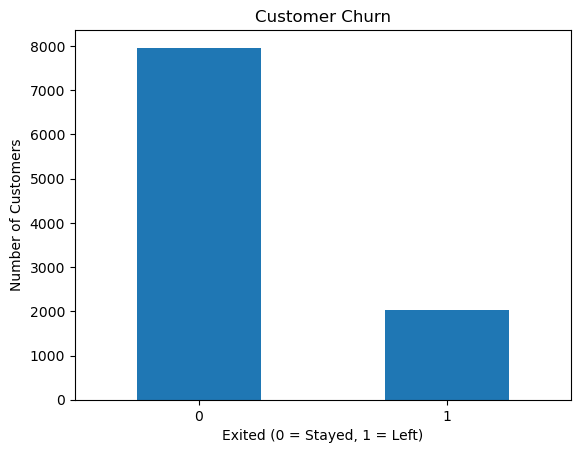

In [25]:
churn_count = df['Exited'].value_counts().sort_index()

churn_count.plot(kind='bar')

plt.title('Customer Churn')
plt.xlabel('Exited (0 = Stayed, 1 = Left)')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

In [26]:
#Customer Churn by Geography

In [27]:
churn_geo=df.groupby('Geography')['Exited'].mean() * 100

churn_geo

Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64

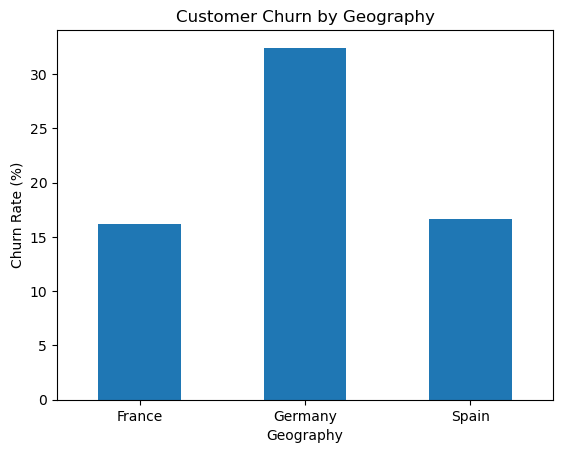

In [28]:
churn_geo.plot(kind='bar')

plt.title('Customer Churn by Geography')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [29]:
#Customer Churn by Age Group

In [30]:
df.loc[df['Age'] < 30, 'AgeGroup'] = 'Under 30'
df.loc[(df['Age'] >= 30) & (df['Age'] < 40), 'AgeGroup'] = '30-39'
df.loc[(df['Age'] >= 40) & (df['Age'] < 50), 'AgeGroup'] = '40-49'
df.loc[(df['Age'] >= 50) & (df['Age'] < 60), 'AgeGroup'] = '50-59'
df.loc[df['Age'] >= 60, 'AgeGroup'] = '60 and above'

In [31]:
churn_age = df.groupby('AgeGroup')['Exited'].mean() * 100

churn_age

AgeGroup
30-39           10.883571
40-49           30.786860
50-59           56.041427
60 and above    27.946768
Under 30         7.556368
Name: Exited, dtype: float64

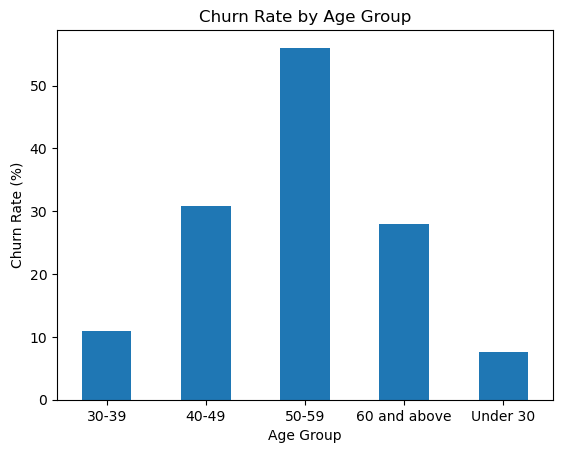

In [32]:
churn_age.plot(kind='bar')

plt.title('Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [33]:
#Churn by number of products

In [34]:
churn_products = df.groupby('NumOfProducts')['Exited'].mean() * 100
churn_products

NumOfProducts
1     27.714398
2      7.581699
3     82.706767
4    100.000000
Name: Exited, dtype: float64

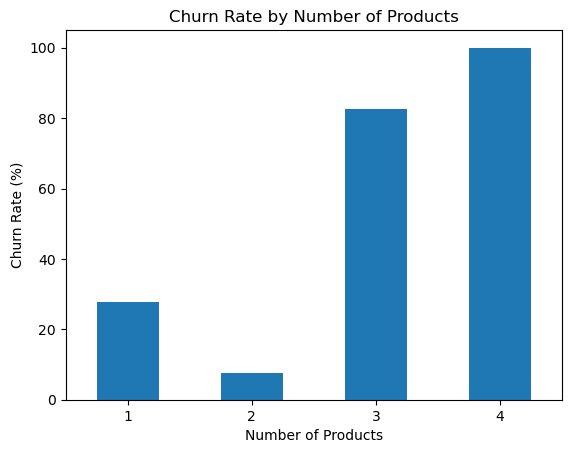

In [35]:
churn_products.plot(kind='bar')

plt.title('Churn Rate by Number of Products')
plt.xlabel('Number of Products')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [36]:
df['NumOfProducts'].value_counts().sort_index()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [37]:
#Churn by customer activity

In [38]:
churn_active = df.groupby('IsActiveMember')['Exited'].mean() * 100
churn_active

IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64

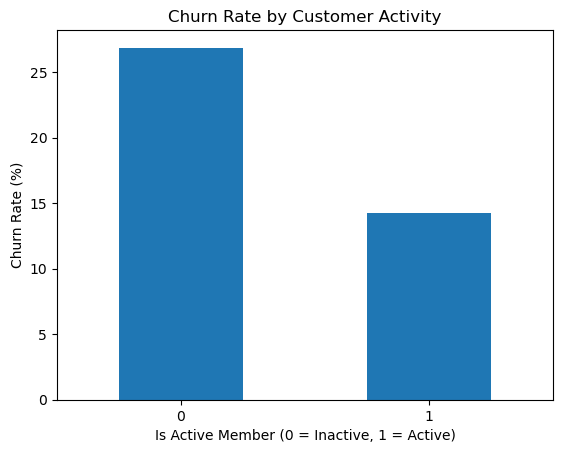

In [39]:
churn_active.plot(kind='bar')

plt.title('Churn Rate by Customer Activity')
plt.xlabel('Is Active Member (0 = Inactive, 1 = Active)')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [41]:
df.to_csv("cleaned_churn_data.csv", index=False)